## Assignment 1 --> House Price Prediction ::::: A Regression Assignment

### Name ::: Rohit

### Roll Number ::: 2501060098

## 1. Importing Required Libraries

In this section, we import all the Python libraries and modules required for data manipulation, exploratory data analysis, visualization, data preprocessing, regression modelling, model evaluation, cross-validation, and model persistence.

These libraries will be used throughout the project, so we import them once at the beginning to maintain a clean and organized workflow.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing and splitting
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler

# Regression algorithms
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Model pipeline
from sklearn.pipeline import Pipeline

# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Model persistence
import joblib

## 2. Loading the Dataset

We load the House Price Regression Dataset using Pandas. The dataset contains the input features required to predict house prices.

The CSV file is stored in a Pandas DataFrame named `df`, which will be used for further analysis and model development.

In [2]:
df = pd.read_csv('house_price_regression_dataset.csv')

### 2.1 Previewing the First Five Records

We use the `head()` method to display the first five rows of the dataset. This helps us understand the structure of the data and identify the available features.

In [3]:
df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


### 2.2 Previewing the Last Five Records

We use the `tail()` method to display the last five rows of the dataset and verify the records at the end of the DataFrame.

In [4]:
df.tail()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
995,3261,4,1,1978,2.165110,2,10,701493.997069
996,3179,1,2,1999,2.977123,1,10,683723.160704
997,2606,4,2,1962,4.055067,0,2,572024.023634
998,4723,5,2,1950,1.930921,0,7,964865.298639
999,3268,4,2,1983,3.108790,2,2,742599.253332


### 2.3 Understanding Dataset Information

The `info()` method provides information about the dataset, including column names, data types, number of non-null values, and memory usage. This helps us understand the structure and quality of the dataset.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### 2.4 Statistical Summary

We use the `describe()` method to generate descriptive statistics for numerical columns, including count, mean, standard deviation, minimum, maximum, and quartile values.

In [6]:
df.describe()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


### 2.5 Dataset Dimensions

We check the shape of the dataset to identify the total number of rows and columns. This provides an overview of the dataset's size.

In [7]:
df.shape

(1000, 8)

### 2.6 Identifying Dataset Features

We display all column names to identify the available independent variables and the target variable used for house price prediction.

In [8]:
df.columns

Index(['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built',
       'Lot_Size', 'Garage_Size', 'Neighborhood_Quality', 'House_Price'],
      dtype='object')

## 3. Data Quality Analysis

### 3.1 Checking Missing Values

We check every column for missing values using `isnull().sum()`. Missing values can affect model training and should be identified before preprocessing.

In [9]:
df.isnull().sum()

Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64

### 3.2 Checking Duplicate Records

We identify duplicate rows in the dataset using the `duplicated()` method. Duplicate records can introduce unwanted bias and affect the reliability of model evaluation.

In [10]:
df[df.duplicated()]

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price


### 3.3 Correlation Analysis

We calculate the correlation coefficients between numerical features to understand their relationships. Correlation analysis helps identify features that have strong relationships with the target variable, House Price.

In [11]:
df.corr()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
Square_Footage,1.000000,-0.043564,-0.031584,-0.022392,0.089479,0.030593,-0.008357,0.991261
Num_Bedrooms,-0.043564,1.000000,0.022848,-0.015820,-0.009355,0.113761,-0.049024,0.014633
Num_Bathrooms,-0.031584,0.022848,1.000000,-0.021063,0.034923,0.024846,0.017585,-0.001862
Year_Built,-0.022392,-0.015820,-0.021063,1.000000,-0.061050,-0.025485,-0.009549,0.051967
Lot_Size,0.089479,-0.009355,0.034923,-0.061050,1.000000,0.002436,0.037630,0.160412
Garage_Size,0.030593,0.113761,0.024846,-0.025485,0.002436,1.000000,-0.011287,0.052133
Neighborhood_Quality,-0.008357,-0.049024,0.017585,-0.009549,0.037630,-0.011287,1.000000,-0.007770
House_Price,0.991261,0.014633,-0.001862,0.051967,0.160412,0.052133,-0.007770,1.000000


### 3.4 Visualizing Feature Correlations

We create a correlation heatmap using Seaborn to visualize relationships between numerical variables.

The heatmap helps identify positively and negatively correlated features and provides a visual understanding of their relationships.

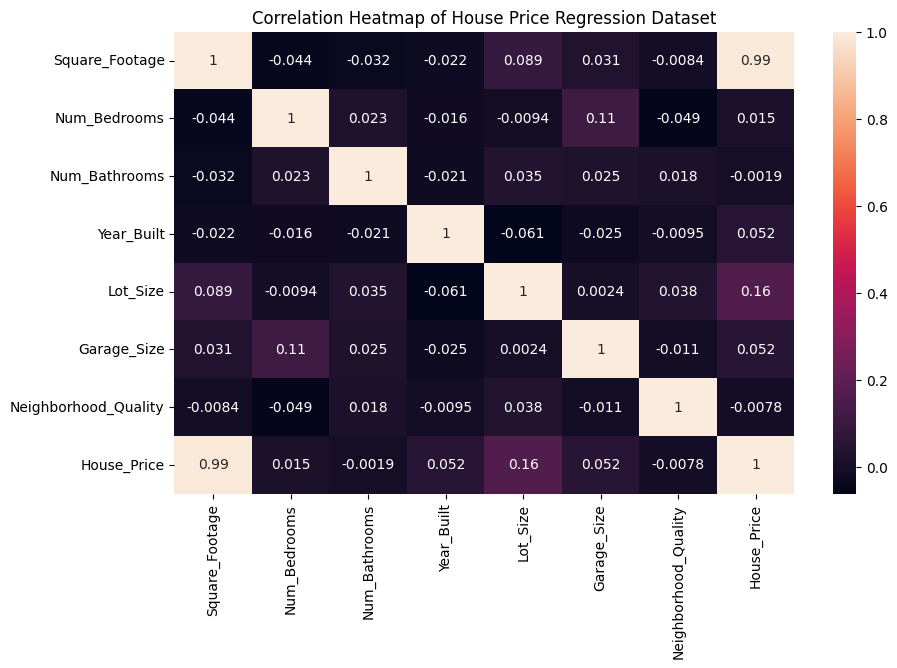

In [12]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True)
plt.title("Correlation Heatmap of House Price Regression Dataset")
plt.show()

## 4. Exploratory Data Analysis

### 4.1 Distribution of House Prices

We use a histogram with a Kernel Density Estimate (KDE) curve to examine the distribution of house prices.

This visualization helps us understand the frequency distribution, spread, and general pattern of the target variable.

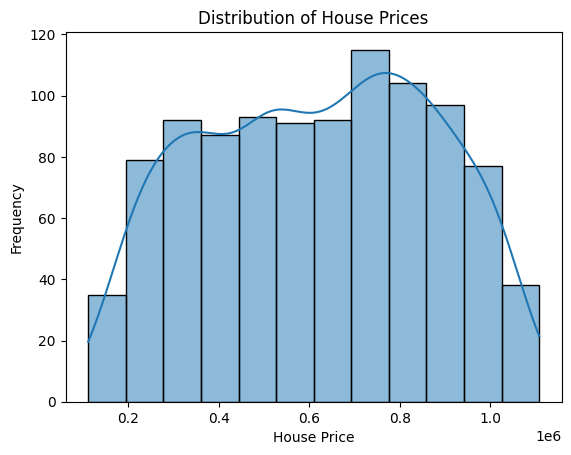

In [13]:
sns.histplot(df["House_Price"], kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")
plt.show()


### 4.2 Average House Price by Number of Bedrooms

We group the dataset by the number of bedrooms and calculate the average house price for each group.

This analysis helps us understand how the number of bedrooms relates to property prices.

In [14]:
avg_price_bedrooms = df.groupby("Num_Bedrooms")["House_Price"].mean()
avg_price_bedrooms

Num_Bedrooms
1    610105.127042
2    601324.699465
3    653491.479508
4    621162.807785
5    612880.757669
Name: House_Price, dtype: float64

### 4.3 Visualizing Average House Prices by Bedrooms

We visualize the average house price for different bedroom counts using a bar chart. This makes comparisons between property configurations easier.

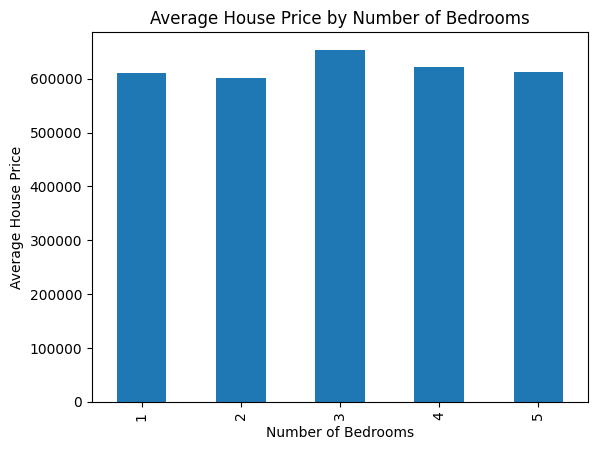

In [15]:
avg_price_bedrooms.plot(kind="bar")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Average House Price")
plt.title("Average House Price by Number of Bedrooms")
plt.show()

### 4.4 Distribution of Individual Features

We generate histograms with KDE curves for the numerical features in the dataset.

This helps examine the distribution, variation, and potential skewness of individual variables.

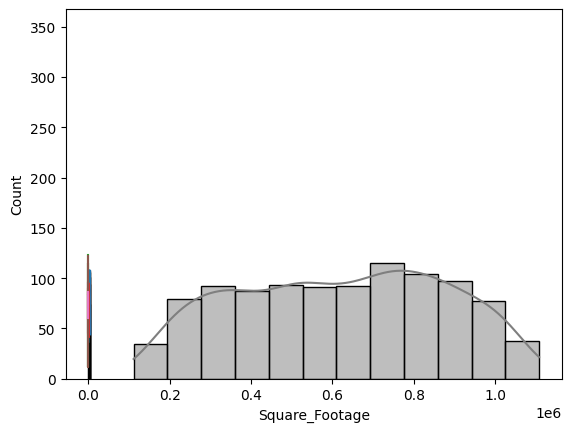

In [16]:
for i in df.columns:
    sns.histplot(df[i], kde=True)

### 4.5 Pairwise Feature Relationships

We use a pair plot to visualize pairwise relationships between numerical features.

The diagonal displays individual feature distributions, while the remaining plots show relationships between pairs of variables.

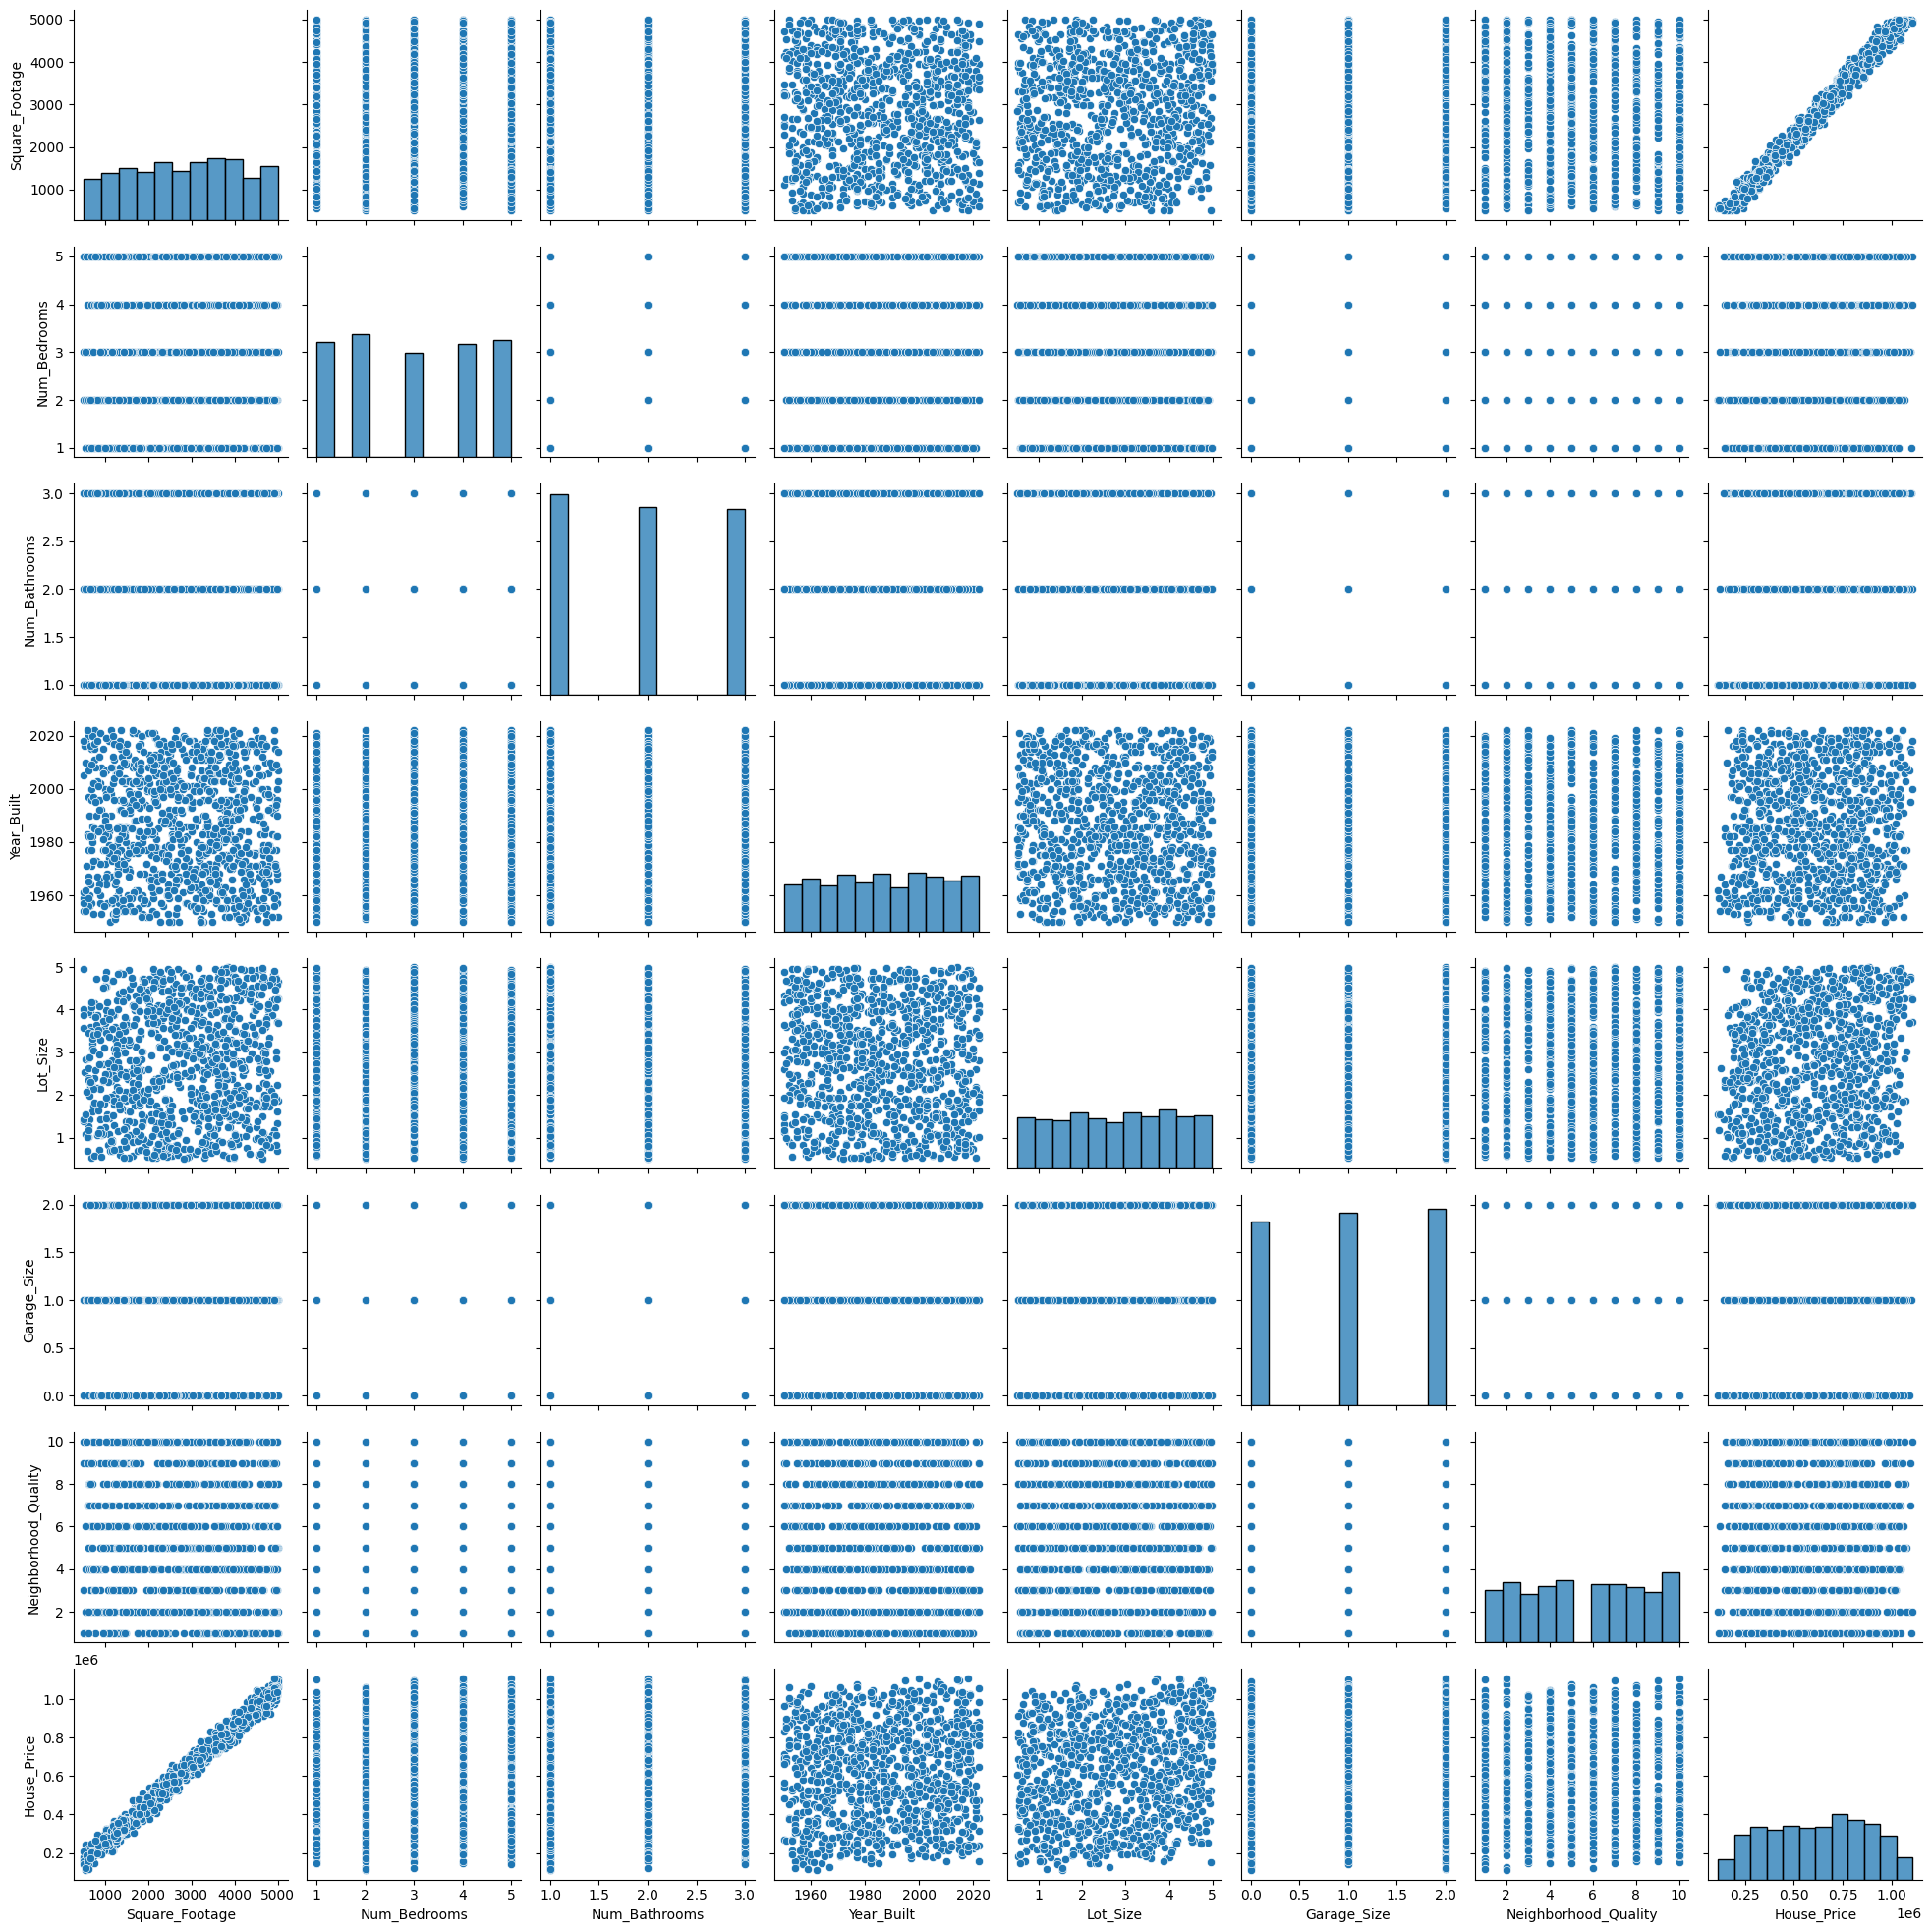

In [17]:
sns.pairplot(df)

### 4.6 Average House Price by Garage Size

We group the dataset by garage size and calculate the average house price for each category.

This analysis helps us explore the relationship between garage size and property prices.

In [18]:
avg_price_garage = df.groupby("Garage_Size")["House_Price"].mean()
avg_price_garage

Garage_Size
0    606031.505225
1    611342.956693
2    638232.279944
Name: House_Price, dtype: float64

### 4.7 Visualizing Average House Prices by Garage Size

We create a bar chart to compare average house prices across different garage sizes and identify possible pricing patterns.

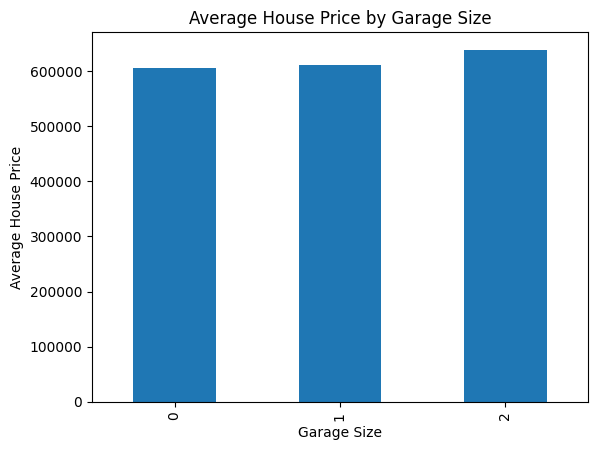

In [19]:
avg_price_garage.plot(kind="bar")
plt.xlabel("Garage Size")
plt.ylabel("Average House Price")
plt.title("Average House Price by Garage Size")
plt.show()

### 4.8 Calculating Average Feature Values

We calculate the mean of each independent numerical feature, excluding the target variable.

This provides a numerical summary of the average values of the input features.

In [20]:
feature_means = df.drop("House_Price", axis=1).mean()
feature_means

Square_Footage          2815.422000
Num_Bedrooms               2.990000
Num_Bathrooms              1.973000
Year_Built              1986.550000
Lot_Size                   2.778087
Garage_Size                1.022000
Neighborhood_Quality       5.615000
dtype: float64

### 4.9 Visualizing Average Feature Values

We use a bar chart to visualize the average values of individual input features. This provides a comparative overview of their numerical scales.

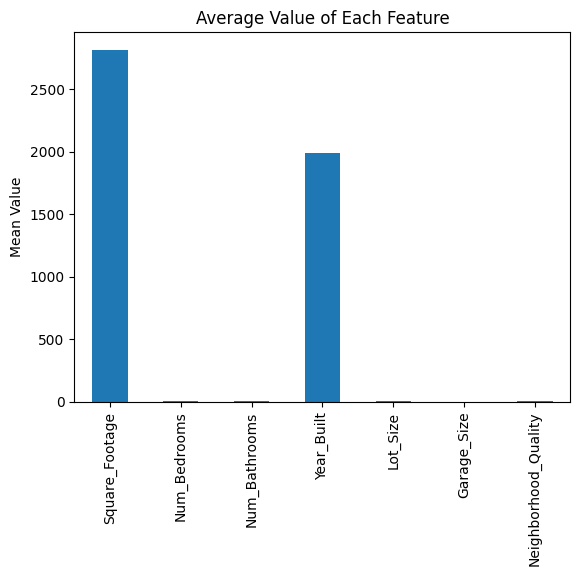

In [21]:
feature_means.plot(kind="bar")
plt.title("Average Value of Each Feature")
plt.ylabel("Mean Value")
plt.show()

### 4.10 Reviewing the Complete Dataset

We display the complete DataFrame to review the dataset after performing the initial exploratory analysis.

In [22]:
df

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06
...,...,...,...,...,...,...,...,...
995,3261,4,1,1978,2.165110,2,10,7.014940e+05
996,3179,1,2,1999,2.977123,1,10,6.837232e+05
997,2606,4,2,1962,4.055067,0,2,5.720240e+05
998,4723,5,2,1950,1.930921,0,7,9.648653e+05


## 5. Feature Selection

We separate the dataset into independent variables (X) and the dependent target variable (y).

- **X:** Contains all input features used for prediction.
- **y:** Contains the House Price values that the regression models will learn to predict.

This separation is necessary before training machine learning models.

In [23]:
X = df.drop('House_Price', axis = 1)
y = df['House_Price']

### 5.1 Checking Independent Feature Dimensions

We check the dimensions of X to identify the number of observations and independent features available for model training.

In [24]:
X.shape

(1000, 7)

### 5.2 Checking Target Variable Dimensions

We check the dimensions of y to verify the number of target observations available for prediction.

In [25]:
y.shape

(1000,)

### 5.3 Previewing Independent Features

We display the first five records of X to verify that the independent features have been extracted correctly.

In [26]:
X.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality
0,1360,2,1,1981,0.599637,0,5
1,4272,3,3,2016,4.753014,1,6
2,3592,1,2,2016,3.634823,0,9
3,966,1,2,1977,2.730667,1,8
4,4926,2,1,1993,4.699073,0,8


## 6. Splitting the Dataset

We divide the dataset into training and testing subsets using `train_test_split()`.

- 85% of the data is allocated for training.
- 15% of the data is reserved for testing.

The random state ensures reproducibility, allowing us to obtain the same split when the code is executed again.

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X,y, train_size = 0.85, random_state = 42)

### 6.1 Initializing Feature Scaling

We initialize the StandardScaler, which standardizes numerical features by removing the mean and scaling them to unit variance.

Feature scaling is particularly useful for algorithms such as Linear Regression with regularization, Ridge, Lasso, and Elastic Net.

In [28]:
scaler = StandardScaler()


### 6.2 Scaling Training Features

We fit the scaler on the training data and transform the training features.

The scaler learns the mean and standard deviation from the training data only, helping prevent data leakage.

In [29]:
X_train_scaled = scaler.fit_transform(X_train)

### 6.3 Scaling Testing Features

We transform the testing features using the scaler fitted on the training data.

We do not fit the scaler again on the testing data because the test set must remain independent of the training process.

In [30]:
X_test_scaled = scaler.transform(X_test)

## 7. Building and Training Regression Models

We train and compare multiple regression algorithms to identify which model performs best on the house price prediction dataset.

The algorithms include:

1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. Elastic Net

We evaluate their predictive performance using R² Score and Root Mean Squared Error (RMSE).

In [31]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Elastic Net": ElasticNet()
}

best_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    
    y_pred = model.predict(X_test_scaled)
    
    best_models[name] = {
        "R2 Score": r2_score(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred))
    }

best_models

{'Linear Regression': {'R2 Score': 0.9983377048996545,
  'RMSE': np.float64(10389.510456470643)},
 'Ridge Regression': {'R2 Score': 0.9983202837956233,
  'RMSE': np.float64(10443.810379790642)},
 'Lasso Regression': {'R2 Score': 0.9983377043447222,
  'RMSE': np.float64(10389.51219066153)},
 'Elastic Net': {'R2 Score': 0.8810875477320201,
  'RMSE': np.float64(87872.84547346606)}}

## 8. Decision Tree Regression

Decision Tree Regression is a supervised learning algorithm that predicts continuous values by dividing the dataset into smaller regions using decision rules.

We initialize a Decision Tree Regressor to explore its performance on the house price prediction problem.

For Decision Tree

In [32]:
decision_model = DecisionTreeRegressor()

### 8.1 Training the Decision Tree Model

We train the Decision Tree Regressor using the training dataset. The model learns patterns and relationships between the input features and house prices.

In [33]:
decision_model.fit(X_train, y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max

### 8.2 Making Predictions

We use the trained Decision Tree model to predict house prices for the unseen testing dataset.

In [34]:
y_preds = decision_model.predict(X_test)

### 8.3 Evaluating Decision Tree Performance

We evaluate the Decision Tree model using:

- R² Score: Measures how well the model explains the variation in house prices.
- RMSE: Measures the average magnitude of prediction errors, with greater emphasis on larger errors.

These metrics help us understand the model's predictive performance.

In [35]:
decision_results = {
    "r2Score": r2_score(y_test, y_preds),
    "rmse": np.sqrt(mean_squared_error(y_test, y_preds))
}

decision_results

{'r2Score': 0.9857289116784941, 'rmse': np.float64(30441.746778879336)}

## 9. Random Forest Regression

Random Forest Regression is an ensemble learning algorithm that combines predictions from multiple decision trees.

By aggregating predictions from several trees, it can improve predictive stability and reduce overfitting compared with an individual decision tree.

For Random Forest

In [36]:
random_model = RandomForestRegressor()

### 9.1 Training the Random Forest Model

We train the Random Forest Regressor using the training dataset. The algorithm builds multiple decision trees and combines their predictions.

In [37]:
random_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

### 9.2 Making Predictions

We use the trained Random Forest model to predict house prices for the testing dataset.

In [38]:
y_preds = random_model.predict(X_test)

### 9.3 Evaluating Random Forest Performance

We calculate the R² Score and RMSE to measure the predictive performance of the Random Forest model on unseen testing data.

In [39]:
random_results = {
    "r2Score": r2_score(y_test, y_preds),
    "rmse": np.sqrt(mean_squared_error(y_test, y_preds))
}

random_results

{'r2Score': 0.9938286387900647, 'rmse': np.float64(20018.498753197404)}

## 10. Model Comparison Using 5-Fold Cross-Validation

Cross-validation provides a more reliable estimate of model performance by evaluating the models across multiple training and validation splits.

We use 5-Fold Cross-Validation with shuffling and a fixed random state.

A Pipeline combines StandardScaler and the regression algorithm so that scaling is fitted independently within each cross-validation training fold.

We compare Linear Regression, Ridge, Lasso, and Random Forest using:

- Mean CV R²: Average R² score across five folds.
- Standard Deviation of CV R²: Measures variation in performance across the folds.

The cross-validation process uses the training data only, keeping the testing data independent for final evaluation.

In [40]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="r2"
    )

    results.append({
        "Model": name,
        "Mean CV R2": scores.mean(),
        "Std CV R2": scores.std()
    })

pd.DataFrame(results).sort_values(
    by="Mean CV R2", ascending=False
)


,Model,Mean CV R2,Std CV R2
0,Linear Regression,0.998500,0.000203
2,Lasso,0.998500,0.000203
1,Ridge,0.998498,0.000200
3,Random Forest,0.992359,0.001286


## 11. Final Model Selection and Evaluation

Based on the cross-validation comparison, we select Linear Regression as the final candidate model.

We create a Pipeline containing StandardScaler and Linear Regression to ensure that preprocessing and prediction are performed consistently.

The selected model is trained using the training dataset and evaluated on the previously reserved testing dataset.

In [41]:
# Create the final candidate model
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Train using training data only
final_model.fit(X_train, y_train)

# Predict on unseen test data
y_pred = final_model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("FINAL MODEL EVALUATION")
print("----------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


FINAL MODEL EVALUATION
----------------------
MAE: 8384.713274475082
MSE: 107941927.52511284
RMSE: 10389.510456470643
R2 Score: 0.9983377048996545


## 12. Model Performance Visualization

### 12.1 Actual vs Predicted House Prices

We create a scatter plot to compare actual house prices with the values predicted by the final Linear Regression model.

The dashed diagonal line represents perfect predictions. Points closer to this line indicate better predictive performance.

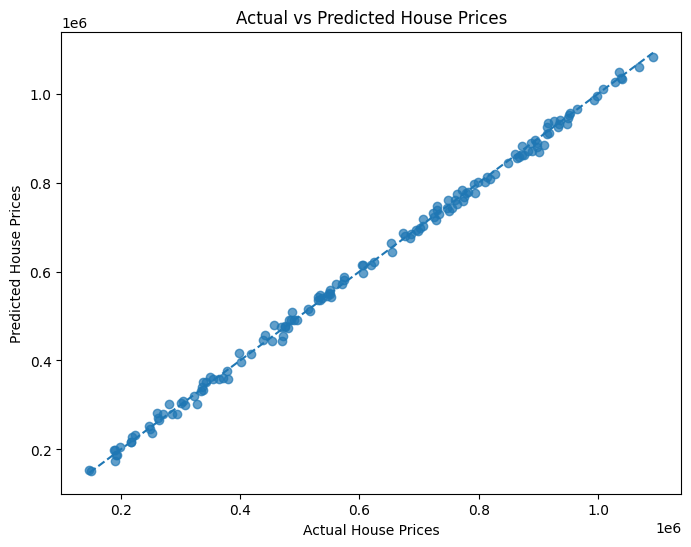

In [42]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()


### 12.2 Residual Analysis

Residuals represent the differences between actual and predicted house prices.

We visualize residuals against predicted values to examine the distribution of prediction errors.

A random distribution of residuals around zero generally indicates that the model does not exhibit an obvious systematic prediction pattern.

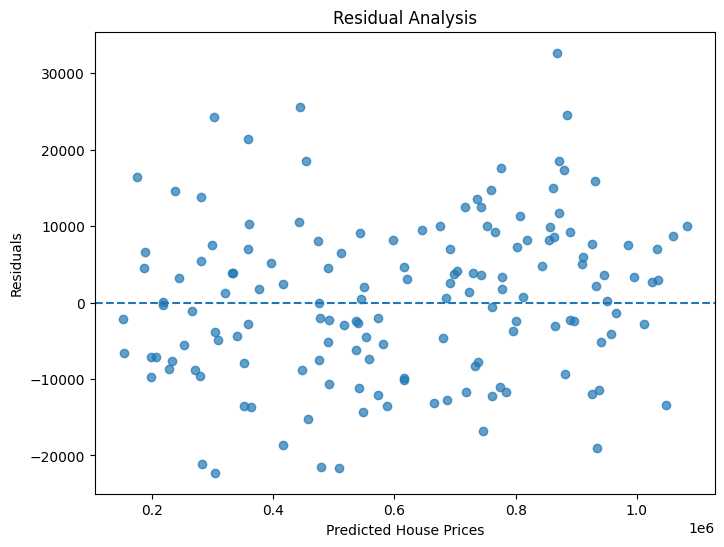

In [43]:

residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.7)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Analysis")

plt.show()


### 12.3 Actual vs Predicted Price Comparison

We create a comparison table containing the actual house prices and their corresponding predicted values for the first five test samples.

The Difference column represents the difference between the actual and predicted prices. This helps us understand how close the model's predictions are to the actual values.

In [46]:
# Compare actual and predicted house prices

comparison = pd.DataFrame({
    "Actual Price": y_test.iloc[:5].values,
    "Predicted Price": y_pred[:5]
})

comparison["Difference"] = (
    comparison["Actual Price"] -
    comparison["Predicted Price"]
)

comparison

,Actual Price,Predicted Price,Difference
0,9.010005e+05,8.683041e+05,32696.368163
1,4.945375e+05,4.899876e+05,4549.879842
2,9.494042e+05,9.458459e+05,3558.293459
3,1.040389e+06,1.033350e+06,7039.098416
4,7.940100e+05,7.763578e+05,17652.239826


## 13. Model Persistence

### 13.1 Saving the Trained Model

We save the trained final model using Joblib in a `.pkl` file.

This allows us to reuse the trained model later without having to repeat the complete training process.

In [48]:
joblib.dump(
    final_model,
    "house_price_prediction_model.pkl"
)

print("Model saved successfully!")


Model saved successfully!


### 13.2 Loading the Saved Model

We load the previously saved model using Joblib to verify that it can be reused for future predictions.

This demonstrates model persistence and allows us to perform predictions without retraining the model.

In [49]:
loaded_model = joblib.load(
    "house_price_prediction_model.pkl"
)

prediction = loaded_model.predict(X_test)
print("Actual Price:", y_test.iloc[0])
print("Predicted Price:", prediction[0])

Actual Price: 901000.4882338208
Predicted Price: 868304.1200703849


### 13.3 Generating Predictions Using the Loaded Model

We use the loaded model to generate predictions on the testing dataset.

This confirms that the saved model can successfully reproduce predictions without requiring the model to be trained again.

We also display an example of an actual house price alongside its predicted price to demonstrate the model's functionality.

## 14. Conclusion

In this assignment, we developed a House Price Prediction system using supervised machine learning and regression algorithms.

We explored the dataset, performed feature selection, prepared the training and testing datasets, and implemented multiple regression models.

We evaluated model performance using R² Score, RMSE, MAE, and 5-Fold Cross-Validation.

Based on the cross-validation results, Linear Regression was selected as the final candidate model, achieving a test R² score of approximately 0.99834.

We also implemented model persistence using Joblib, allowing the trained model to be saved, loaded, and reused for future predictions without retraining.

This assignment provided practical experience in the complete machine learning workflow, from data preparation and model training to evaluation and deployment readiness.